#Taller 1: Teoría de Aprendizaje de Máquina – 2026-2
**Profesor:** Diego Armando Pérez Rosero  
**Estudiante:** Laura Sofia Castaño Pineda

---


## 1. Clasificación lineal y algoritmo del perceptrón

### 1.1 Frontera de decisión
Dados los parámetros $w = \begin{bmatrix} 1 \\ 2 \end{bmatrix}$ y $b = -3$, la ecuación de la frontera de decisión $w^\top x + b = 0$ es:

$$1 \cdot x_{(1)} + 2 \cdot x_{(2)} - 3 = 0 \implies x_{(2)} = -0.5x_{(1)} + 1.5$$

Esta recta tiene pendiente $m = -0.5$ e intercepta los ejes en $(0, 1.5)$ y $(3, 0)$. Aplicando la regla de decisión ($\hat{y} = +1$ si $w^\top x + b > 0$, y $\hat{y} = -1$ si $w^\top x + b \le 0$), obtenemos:

| Punto ($x_i$) | Evaluación ($w^\top x_i + b$) | Clase ($\hat{y}_i$) | Justificación geométrica |
| :--- | :---: | :---: | :--- |
| **$x_1 = (0,0)$** | $1(0) + 2(0) - 3 = -3 \le 0$ | **$-1$** | Se ubica por debajo de la recta (semiplano negativo). |
| **$x_2 = (1,0)$** | $1(1) + 2(0) - 3 = -2 \le 0$ | **$-1$** | Se ubica por debajo de la recta (semiplano negativo). |
| **$x_3 = (2,1)$** | $1(2) + 2(1) - 3 = +1 > 0$ | **$+1$** | Se ubica por encima de la recta (semiplano positivo). |
| **$x_4 = (3,1)$** | $1(3) + 2(1) - 3 = +2 > 0$ | **$+1$** | Se ubica por encima de la recta (semiplano positivo). |

---

### 1.2 Actualización del perceptrón
Partiendo de la definición del margen $m_i = y_i(w^\top x_i + b)$ y aplicando las reglas de actualización $w_{\text{nuevo}} = w + \eta y_i x_i$ y $b_{\text{nuevo}} = b + \eta y_i$ ante un error de clasificación:

$$
\begin{aligned}
m_{i,\text{nuevo}} &= y_i\left(w_{\text{nuevo}}^\top x_i + b_{\text{nuevo}}\right) \\
&= y_i\left((w + \eta y_i x_i)^\top x_i + b + \eta y_i\right) \\
&= y_i(w^\top x_i + b) + \eta y_i^2 (x_i^\top x_i + 1)
\end{aligned}
$$

Dado que $y_i \in \{-1, +1\} \implies y_i^2 = 1$ y que $x_i^\top x_i = \|x_i\|_2^2$, se obtiene:

$$m_{i,\text{nuevo}} = m_i + \eta\left(\|x_i\|_2^2 + 1\right)$$

**Implicación:** Como $\eta > 0$ y $\|x_i\|_2^2 \ge 0$, el término $\eta(\|x_i\|_2^2 + 1)$ es estrictamente positivo. Esto garantiza que cada actualización incrementa el margen ($m_{i,\text{nuevo}} > m_i$), desplazando la frontera de decisión en la dirección necesaria para corregir el error sobre la observación.

---

### 1.3 Ejercicio numérico
Con $w = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$, $b = 0$, $\eta = 0.5$, $x = \begin{bmatrix} 2 \\ 1 \end{bmatrix}$ y $y = +1$:

1. **Verificación de error:**  
   $$w^\top x + b = 0(2) + 0(1) + 0 = 0 \le 0 \implies \hat{y} = -1$$
   Como $\hat{y} = -1 \ne y = +1$ (margen inicial $m = 0$), la observación está mal clasificada y **sí corresponde actualizar**.

2. **Parámetros actualizados:**
   * **Pesos:** $w_{\text{nuevo}} = \begin{bmatrix} 0 \\ 0 \end{bmatrix} + 0.5(+1)\begin{bmatrix} 2 \\ 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 0.5 \end{bmatrix}$
   * **Sesgo:** $b_{\text{nuevo}} = 0 + 0.5(+1) = 0.5$

3. **Nuevo margen:**
   $$m_{\text{nuevo}} = (+1)\left(\begin{bmatrix} 1 & 0.5 \end{bmatrix}\begin{bmatrix} 2 \\ 1 \end{bmatrix} + 0.5\right) = 2 + 0.5 + 0.5 = 3$$

=== Resultados Punto 1.1 ===
x1 (0,0): w^T x + b = -3  ->  y_hat = -1
x2 (1,0): w^T x + b = -2  ->  y_hat = -1
x3 (2,1): w^T x + b = +1  ->  y_hat = +1
x4 (3,1): w^T x + b = +2  ->  y_hat = +1


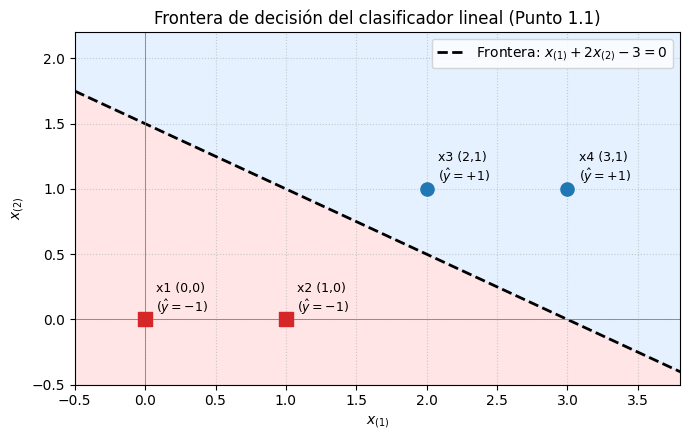


=== Resultados Punto 1.3 ===
Predicción inicial: -1 (Real: +1) -> ¿Actualizar?: True
w_nuevo = [1.  0.5]
b_nuevo = 0.5
m_nuevo = 3.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Punto 1.1: Frontera de decisión y clasificación ---
w = np.array([1, 2])
b = -3

X_pts = np.array([[0, 0], [1, 0], [2, 1], [3, 1]])
etiquetas_pts = ['x1 (0,0)', 'x2 (1,0)', 'x3 (2,1)', 'x4 (3,1)']

scores = X_pts @ w + b
y_pred = np.where(scores > 0, 1, -1)

print("=== Resultados Punto 1.1 ===")
for nombre, score, pred in zip(etiquetas_pts, scores, y_pred):
    print(f"{nombre}: w^T x + b = {score:+d}  ->  y_hat = {pred:+d}")

# Gráfica
xx, yy = np.meshgrid(np.linspace(-0.5, 4, 200), np.linspace(-0.5, 2.5, 200))
Z = w[0] * xx + w[1] * yy + b

plt.figure(figsize=(7, 4.5))
plt.contourf(xx, yy, Z, levels=[-100, 0, 100], colors=['#ffcccc', '#cce5ff'], alpha=0.5)

x_recta = np.linspace(-0.5, 4, 100)
plt.plot(x_recta, -0.5 * x_recta + 1.5, 'k--', lw=2, label='Frontera: $x_{(1)} + 2x_{(2)} - 3 = 0$')

for pt, nombre, pred in zip(X_pts, etiquetas_pts, y_pred):
    color = 'tab:blue' if pred == 1 else 'tab:red'
    marker = 'o' if pred == 1 else 's'
    plt.scatter(pt[0], pt[1], color=color, marker=marker, s=90, zorder=5)
    plt.annotate(f"{nombre}\n($\\hat{{y}}={pred:+d}$)", (pt[0] + 0.08, pt[1] + 0.06), fontsize=9)

plt.axhline(0, color='gray', lw=0.6)
plt.axvline(0, color='gray', lw=0.6)
plt.xlim(-0.5, 3.8)
plt.ylim(-0.5, 2.2)
plt.xlabel('$x_{(1)}$')
plt.ylabel('$x_{(2)}$')
plt.title('Frontera de decisión del clasificador lineal (Punto 1.1)')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Punto 1.3: Verificación numérica ---
w_0 = np.array([0.0, 0.0])
b_0 = 0.0
eta = 0.5
x_ej = np.array([2.0, 1.0])
y_ej = 1

score_0 = w_0 @ x_ej + b_0
y_hat_0 = 1 if score_0 > 0 else -1

print("\n=== Resultados Punto 1.3 ===")
print(f"Predicción inicial: {y_hat_0:+d} (Real: {y_ej:+d}) -> ¿Actualizar?: {y_hat_0 != y_ej}")

if y_hat_0 != y_ej:
    w_nuevo = w_0 + eta * y_ej * x_ej
    b_nuevo = b_0 + eta * y_ej
    m_nuevo = y_ej * (w_nuevo @ x_ej + b_nuevo)
    print(f"w_nuevo = {w_nuevo}")
    print(f"b_nuevo = {b_nuevo}")
    print(f"m_nuevo = {m_nuevo}")

## 2. Clasificación por los $k$ vecinos más cercanos ($k$-NN)

### 2.1 Cálculo manual de distancias y clasificación
Dado el punto de consulta $q = (1,1)$ y el conjunto de entrenamiento en $\mathbb{R}^2$ (corrigiendo el error tipográfico de la guía en $x_5 = (1,1)$), calculamos la distancia euclidiana $d(q, x_i) = \sqrt{(q_1 - x_{i,1})^2 + (q_2 - x_{i,2})^2}$:

| Orden | Observación ($x_i$) | Clase | Cálculo de distancia | Valor exacto | Aprox. |
| :---: | :---: | :---: | :--- | :---: | :---: |
| **1.º** | $x_5 = (1,1)$ | **B** | $\sqrt{(1-1)^2 + (1-1)^2}$ | $0$ | $0.000$ |
| **2.º** | $x_2 = (1,0)$ | **A** | $\sqrt{(1-1)^2 + (1-0)^2}$ | $\sqrt{1}$ | $1.000$ |
| **3.º** | $x_1 = (0,0)$ | **A** | $\sqrt{(1-0)^2 + (1-0)^2}$ | $\sqrt{2}$ | $1.414$ |
| **4.º** | $x_3 = (3,1)$ | **B** | $\sqrt{(1-3)^2 + (1-1)^2}$ | $\sqrt{4}$ | $2.000$ |
| **5.º** | $x_4 = (0,3)$ | **B** | $\sqrt{(1-0)^2 + (1-3)^2}$ | $\sqrt{5}$ | $2.236$ |

**Clasificación por votación mayoritaria:**
* **$k = 1$:** El vecino más cercano es $x_5$ (Clase B). $\implies$ **Clase B** (1 voto B vs. 0 votos A).
* **$k = 3$:** Los 3 vecinos más cercanos son $x_5$ (B), $x_2$ (A) y $x_1$ (A). $\implies$ **Clase A** (2 votos A vs. 1 voto B).
* **$k = 5$:** Los 5 vecinos son $x_5$ (B), $x_2$ (A), $x_1$ (A), $x_3$ (B) y $x_4$ (B). $\implies$ **Clase B** (3 votos B vs. 2 votos A).

**Efecto de $k$:** Un $k$ pequeño responde únicamente al entorno inmediato y es muy sensible a observaciones puntuales; al aumentar $k$, se amplía el vecindario evaluado y la decisión pasa a depender de la densidad regional de cada clase.

---


####2.2: IMPLEMENTACIÓN

=== Verificación Punto 2.1 ===
x5 (1, 1) | Clase: B | d = 0.0000
x2 (1, 0) | Clase: A | d = 1.0000
x1 (0, 0) | Clase: A | d = 1.4142
x3 (3, 1) | Clase: B | d = 2.0000
x4 (0, 3) | Clase: B | d = 2.2361
k = 1 -> Vecinos: ['B'] -> Predicción: Clase B
k = 3 -> Vecinos: ['B', 'A', 'A'] -> Predicción: Clase A
k = 5 -> Vecinos: ['B', 'A', 'A', 'B', 'B'] -> Predicción: Clase B

=== Resultados Punto 2.2 (make_moons) ===
k =  1 | Train Accuracy: 1.0000 | Test Accuracy: 0.9333
k =  5 | Train Accuracy: 0.9571 | Test Accuracy: 0.9556
k = 15 | Train Accuracy: 0.9571 | Test Accuracy: 0.9333


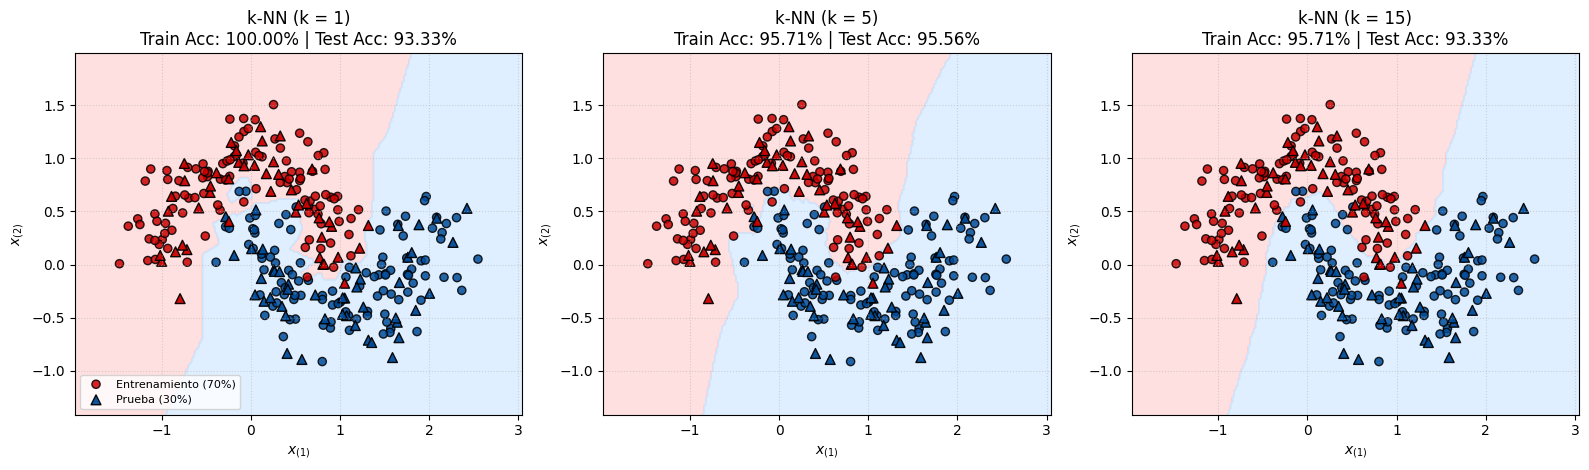

In [ ]:
# -- Punto 2.2. y Verificación del 2.1.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# --- Punto 2.1: Verificación del cálculo manual ---
X_manual = np.array([[0, 0], [1, 0], [3, 1], [0, 3], [1, 1]])
y_manual = np.array(['A', 'A', 'B', 'B', 'B'])
q = np.array([1, 1])

distancias = np.linalg.norm(X_manual - q, axis=1)
orden = np.argsort(distancias)

print("=== Verificación Punto 2.1 ===")
for idx in orden:
    coord = tuple(X_manual[idx].tolist())
    print(f"x{idx+1} {coord} | Clase: {y_manual[idx]} | d = {distancias[idx]:.4f}")

for k in [1, 3, 5]:
    vecinos_y = y_manual[orden[:k]]
    clases, conteos = np.unique(vecinos_y, return_counts=True)
    pred = clases[np.argmax(conteos)]
    print(f"k = {k} -> Vecinos: {vecinos_y.tolist()} -> Predicción: Clase {pred}")



# --- Punto 2.2: Experimentación con make_moons ---

X, y = make_moons(n_samples=300, noise=0.20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

valores_k = [1, 5, 15]
modelos = {}

print("\n=== Resultados Punto 2.2 (make_moons) ===")
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    modelos[k] = knn

    acc_train = accuracy_score(y_train, knn.predict(X_train))
    acc_test = accuracy_score(y_test, knn.predict(X_test))
    print(f"k = {k:2d} | Train Accuracy: {acc_train:.4f} | Test Accuracy: {acc_test:.4f}")

# Gráfica de datos y regiones de decisión para k = 1, 5 y 15
h = 0.02
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

cmap_fondo = ListedColormap(['#ffcccc', '#cce5ff'])
cmap_puntos = ListedColormap(['#cc0000', '#004c99'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, k in zip(axes, valores_k):
    Z = modelos[k].predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_fondo, alpha=0.6)

    # Puntos de entrenamiento (círculos) y prueba (triángulos)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_puntos,
               edgecolor='k', s=35, alpha=0.85, label='Entrenamiento (70%)')
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cmap_puntos,
               marker='^', edgecolor='k', s=50, alpha=0.95, label='Prueba (30%)')

    acc_tr = accuracy_score(y_train, modelos[k].predict(X_train))
    acc_te = accuracy_score(y_test, modelos[k].predict(X_test))
    ax.set_title(f"k-NN (k = {k})\nTrain Acc: {acc_tr:.2%} | Test Acc: {acc_te:.2%}")
    ax.set_xlabel("$x_{(1)}$")
    ax.set_ylabel("$x_{(2)}$")
    ax.grid(True, linestyle=':', alpha=0.5)

axes[0].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

### 2.3 Interpretación y análisis
* **Efecto de $k$ pequeño vs. grande:** Un $k$ muy pequeño ($k=1$) genera **sobreajuste (*overfitting*)** con bajo sesgo y alta varianza, memorizando el ruido de entrenamiento con fronteras irregulares. Un $k$ muy grande ($k \to N$) provoca **subajuste (*underfitting*)** con alto sesgo y baja varianza, suavizando en exceso la frontera hasta perder la estructura no lineal de los datos.
* **Mejor generalización:** El modelo con **$k = 5$** generalizó mejor, logrando la mayor exactitud en prueba (**$95.56\%$**) con una brecha mínima respecto al entrenamiento (**$95.71\%$**).
* **Validación vs. Prueba:** Seleccionar $k$ usando el conjunto de prueba introduce **fuga de información (*data leakage*)**, sesgando de forma optimista la estimación del error de generalización. Por ello, los hiperparámetros deben ajustarse en un conjunto de validación o mediante validación cruzada.

---

## 3. Evaluación de un clasificador binario

### 3.1 Matriz de confusión
Dadas las etiquetas reales $y = [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]$ y las predicciones $\hat{y} = [0, 1, 0, 0, 1, 0, 1, 1, 0, 1]$, tomando la clase $1$ como positiva:

* **Verdaderos Positivos ($\text{TP}$):** $4$ (posiciones 5, 7, 8, 10)
* **Verdaderos Negativos ($\text{TN}$):** $3$ (posiciones 1, 3, 4)
* **Falsos Positivos ($\text{FP}$):** $1$ (posición 2)
* **Falsos Negativos ($\text{FN}$):** $2$ (posiciones 6, 9)

| | Predicho $0$ | Predicho $1$ |
| :--- | :---: | :---: |
| **Real $0$** | $\text{TN} = 3$ | $\text{FP} = 1$ |
| **Real $1$** | $\text{FN} = 2$ | $\text{TP} = 4$ |

---

### 3.2 Cálculo de Métricas
1. **Exactitud (*Accuracy*):**
   $$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}} = \frac{4 + 3}{10} = 0.70 \quad (70.00\%)$$
   *Evalúa:* La proporción global de aciertos sobre el total de predicciones realizadas.

2. **Precisión (*Precision*):**
   $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} = \frac{4}{4 + 1} = \frac{4}{5} = 0.80 \quad (80.00\%)$$
   *Evalúa:* La proporción de predicciones positivas que realmente pertenecen a la clase positiva (confiabilidad de las alarmas positivas).

3. **Sensibilidad (*Recall*):**
   $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}} = \frac{4}{4 + 2} = \frac{4}{6} \approx 0.6667 \quad (66.67\%)$$
   *Evalúa:* La capacidad del clasificador para encontrar todos los casos positivos reales (exhaustividad).

4. **Puntaje $F_1$ (*$F_1$-score*):**
   $$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot 0.80 \cdot (2/3)}{0.80 + (2/3)} = \frac{8}{11} \approx 0.7273 \quad (72.73\%)$$
   *Evalúa:* La media armónica entre *Precision* y *Recall*, resumiendo en un solo indicador el equilibrio entre evitar falsos positivos y evitar falsos negativos.


---

### 3.3 Verificación y Analisis


=== Verificación Punto 3 ===
Matriz de confusión (filas=Real, cols=Predicho):
[[3 1]
 [2 4]]

TP = 4, TN = 3, FP = 1, FN = 2

Accuracy  : 0.7000 (70.00%)
Precision : 0.8000 (80.00%)
Recall    : 0.6667 (66.67%)
F1-score  : 0.7273 (72.73%)


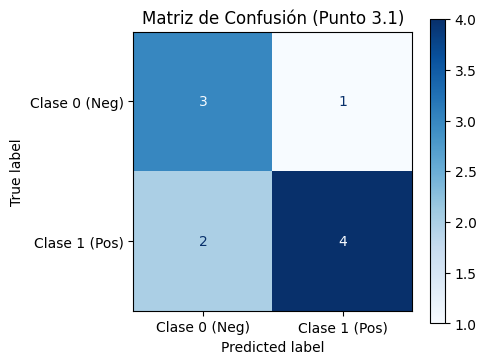

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Etiquetas reales y predicciones dadas en el enunciado
y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_hat = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# Cálculo de la matriz de confusión y desglose de componentes
cm = confusion_matrix(y, y_hat)
tn, fp, fn, tp = cm.ravel()

# Cálculo de métricas con scikit-learn
acc = accuracy_score(y, y_hat)
prec = precision_score(y, y_hat)
rec = recall_score(y, y_hat)
f1 = f1_score(y, y_hat)

print("=== Verificación Punto 3 ===")
print(f"Matriz de confusión (filas=Real, cols=Predicho):\n{cm}\n")
print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}\n")
print(f"Accuracy  : {acc:.4f} ({acc:.2%})")
print(f"Precision : {prec:.4f} ({prec:.2%})")
print(f"Recall    : {rec:.4f} ({rec:.2%})")
print(f"F1-score  : {f1:.4f} ({f1:.2%})")

# Visualización de la matriz de confusión para el informe PDF
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Clase 0 (Neg)', 'Clase 1 (Pos)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('Matriz de Confusión (Punto 3.1)')
plt.tight_layout()
plt.show()

####¿Cuándo nos engaña el $Accuracy$?
1. **Desbalance severo de clases:** En detección de fraude o enfermedades poco frecuentes (ej. $99\%$ clase negativa y $1\%$ clase positiva), un clasificador que siempre prediga la clase mayoritaria obtiene $99\%$ de *Accuracy*, pero es completamente inútil para identificar los casos positivos de interés.
2. **Costos asimétricos de error:** En diagnóstico clínico o seguridad industrial, el *Accuracy* pondera por igual los $\text{FP}$ y los $\text{FN}$, ocultando el impacto crítico de un falso negativo (ej. no detectar una patología grave) frente a un falso positivo.